In [8]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 50.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44286 sha256=024a475e52b87a5b5a4ddaaaf8118d9060f69e26474d60c0c1ee3c30d3e70b0d
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


✅ Modèle chargé correctement

🔬 PRÉDICTION
Classe : pituitary
Confiance : 88.34 %

📊 Probabilités :
glioma : 0.85 %
meningioma : 9.44 %
notumor : 1.37 %
pituitary : 88.34 %


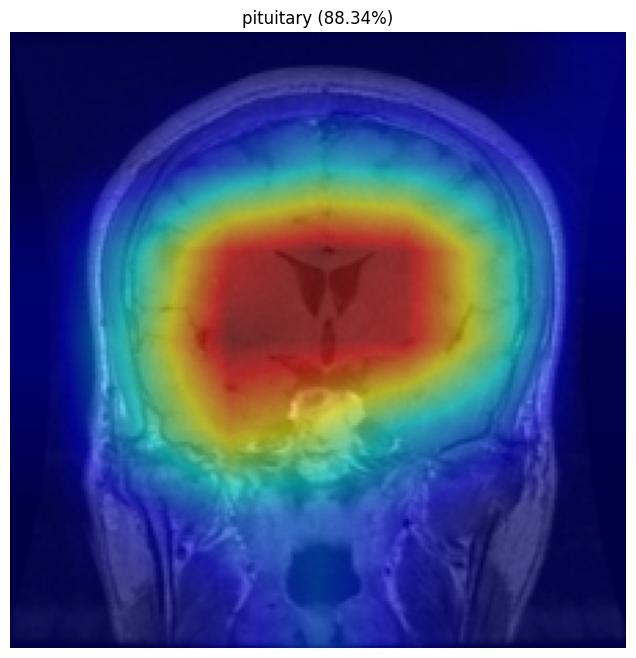

In [29]:
# ============================================================
# 1. IMPORTS
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from torchvision import models, transforms
from PIL import Image

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ============================================================
# 2. CONFIG
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = ["glioma", "meningioma", "notumor", "pituitary"]

MODEL_PATH = "/content/brain_tumor_final_v2.pth"
IMAGE_PATH = "/content/Te-pi_12.jpg"

# ============================================================
# 3. MODEL (EXACT TRAIN ARCHITECTURE)
# ============================================================
model = models.efficientnet_b0(weights=None)

model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(1280, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 4)
)

model = model.to(device)

checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("✅ Modèle chargé correctement")

# ============================================================
# 4. PREPROCESSING (IDENTIQUE TRAINING)
# ============================================================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# ============================================================
# 5. CHARGER IMAGE
# ============================================================
image = Image.open(IMAGE_PATH).convert("RGB")

image_resized = transforms.Resize((224, 224))(image)
image_np = np.array(image_resized) / 255.0  # pour Grad-CAM

input_tensor = transform(image).unsqueeze(0).to(device)

# ============================================================
# 6. PREDICTION
# ============================================================
with torch.no_grad():
    outputs = model(input_tensor)
    probs = torch.softmax(outputs, dim=1)
    conf, pred = torch.max(probs, 1)

pred_class = class_names[pred.item()]

print("\n==============================")
print("🔬 PRÉDICTION")
print("==============================")
print("Classe :", pred_class)
print("Confiance :", round(conf.item()*100, 2), "%")
print("==============================")

# 👉 afficher toutes les probabilités (IMPORTANT)
print("\n📊 Probabilités :")
for i, p in enumerate(probs[0]):
    print(class_names[i], ":", round(p.item()*100, 2), "%")

# ============================================================
# 7. GRAD-CAM (STABLE)
# ============================================================
target_layer = model.features[-1]

cam = GradCAM(
    model=model,
    target_layers=[target_layer]
)

targets = [ClassifierOutputTarget(pred.item())]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

# ============================================================
# 8. VISUALISATION
# ============================================================
visualization = show_cam_on_image(
    image_np,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(8, 8))
plt.imshow(visualization)
plt.title(f"{pred_class} ({conf.item()*100:.2f}%)")
plt.axis("off")
plt.show()